## Statistical analysis of characteristics

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import minimize
from scipy.optimize import root_scalar
import itertools

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statannotations.Annotator import Annotator
from scipy import stats
from scipy.stats import genpareto
import scikit_posthocs as sp
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency

In [2]:
data_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/data"
out_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/out"
fig_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/figures"

## Load data

In [3]:
data = pd.read_pickle(out_path + "/mutation_time_series_with_fitness.pkl")

#Get unique index for each mutation and count parallelism
data_unique = data.groupby(['pos', 'new']).size().reset_index(name='number_of_lines')
data_unique['Index'] = data_unique.index
data_indexed = pd.merge(data, data_unique, on=['pos', 'new'], how='left')

#Add cell type column
data_indexed['cell_type'] = np.floor((data_indexed['line']-13)/2)

#Get beneficial tail
data_ben = data_indexed[data_indexed['s']>0]


## Fit Generalised Pareto Distribution to beneficial tail using likelihood

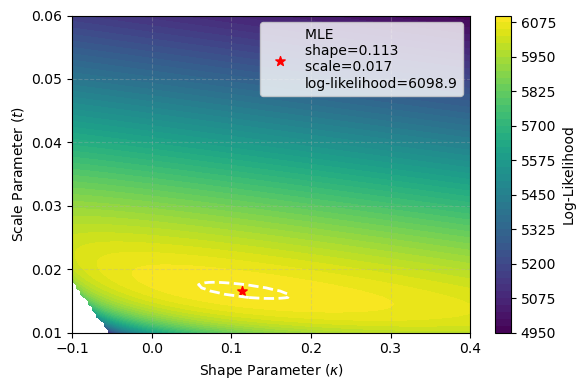

In [4]:
#Fit the GPD to the beneficial tail with loc parameter=0 and find log likelihood
k_vals = np.linspace(-0.1, 0.4, 100) #shape parameter
t_vals = np.linspace(0.01, 0.06, 100) #scale parameter
K, T = np.meshgrid(k_vals, t_vals)
log_likelihood = np.zeros_like(K)

#Calculate log likelihood for each parameter combination
for i in range(K.shape[0]):
    for j in range(K.shape[1]):
        k = K[i, j]
        t = T[i, j]
        
        #For the GPD, if k < 0, 1 + k*(x/t) > 0 for all x
        if k < 0 and np.min(data_ben['s']) >= -t / k:
            log_likelihood[i, j] = -np.inf

        try:
            ll = np.sum(genpareto.logpdf(data_ben['s'], c=k, loc=0, scale=t))
            log_likelihood[i, j] = ll if np.isfinite(ll) else -np.inf
        except:
            log_likelihood[i, j] = -np.inf

log_likelihood[~np.isfinite(log_likelihood)] = np.nan


#Find the ML fit
k_fit, _, t_fit = genpareto.fit(data_ben['s'], floc=0) 
log_likelihood_fit = np.sum(genpareto.logpdf(data_ben['s'], k_fit, 0, t_fit))

#Find the 95% CI for two degrees of freedom
chi2_val_2df = 5.991 
ci_threshold = log_likelihood_fit - (chi2_val_2df / 2)

#Plot
fig, ax = plt.subplots(1,1,figsize=(6, 4))

contour = ax.contourf(K, T, log_likelihood, levels=50, cmap='viridis')
plt.colorbar(contour, label='Log-Likelihood')

cs = plt.contour(K, T, log_likelihood, levels=[ci_threshold], colors='white', linewidths=2, linestyles='--')
ax.clabel(cs, fmt={ci_threshold: '95% Confidence Region'}, colors='white', fontsize=10)

ax.scatter(k_fit, t_fit, color='red', marker='*', s=50, label=f'MLE \nshape={k_fit:.3f} \nscale={t_fit:.3f} \nlog-likelihood={log_likelihood_fit:.1f}')

ax.set_xlabel('Shape Parameter ($\kappa$)')
ax.set_ylabel('Scale Parameter ($t$)')
ax.legend(loc='upper right')
ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()


### Find mean and 95% confidence interval integrating over the other parameter

In [5]:
#Functions to find the MLE and 95% CIs

def mle_ci_k(data,k0,k_lower,k_upper):
    
    #Find MLE of k, and log-likelihood, integrating over t
    def neg_ll_int_t(k):
        _, _, t_fit = genpareto.fit(data, fc=k, floc=0) 
        ll = np.sum(genpareto.logpdf(data, k, 0, t_fit))
        return -ll

    k_mle = minimize(neg_ll_int_t, [k0], method='L-BFGS-B', bounds=[(k_lower,k_upper)]).x[0]
    ll_int_t_max = -minimize(neg_ll_int_t, [k0], method='L-BFGS-B', bounds=[(k_lower,k_upper)]).fun

    #Find 95% CI of k estimate, integrating over t
    chi2_val_1df = 3.841
    ci_threshold = ll_int_t_max - (chi2_val_1df / 2.0)

    def ci_ll(k):
        return neg_ll_int_t(k) + ci_threshold
    ci_left = root_scalar(ci_ll, bracket=[k_lower,k_mle], method='brentq').root
    ci_right = root_scalar(ci_ll, bracket=[k_mle,k_upper], method='brentq').root

    return k_mle, ci_left, ci_right




def mle_ci_mean(data,t0,t_lower,t_upper):

    #Find MLE of t, and log-likelihood, integrating over k
    def neg_ll_int_k(t):
        k_fit,_,_ = genpareto.fit(data, fscale=t, floc=0) 
        ll = np.sum(genpareto.logpdf(data, k_fit, 0, t))
        return -ll

    t_mle = minimize(neg_ll_int_k, [t0], method='L-BFGS-B', bounds=[(t_lower,t_upper)]).x[0]
    ll_int_k_max = -minimize(neg_ll_int_k, [t0], method='L-BFGS-B', bounds=[(t_lower,t_upper)]).fun

    #Find 95% CI of t estimate, integrating over k
    chi2_val_1df = 3.841
    ci_threshold = ll_int_k_max - (chi2_val_1df / 2.0)

    def ci_ll(t):
        return neg_ll_int_k(t) + ci_threshold
    ci_left = root_scalar(ci_ll, bracket=[t_lower,t_mle], method='brentq').root
    ci_right = root_scalar(ci_ll, bracket=[t_mle,t_upper], method='brentq').root

    #Find mean instead
    k_mle,_,_ = genpareto.fit(data, fscale=t_mle, floc=0)
    mean_mle = t_mle/(1-k_mle)
    k_right,_,_ = genpareto.fit(data, fscale=ci_right, floc=0)
    mean_right = ci_right/(1-k_right)
    k_left,_,_ = genpareto.fit(data, fscale=ci_left, floc=0)
    mean_left = ci_left/(1-k_left)

    return mean_mle, mean_left, mean_right


#### Cell types

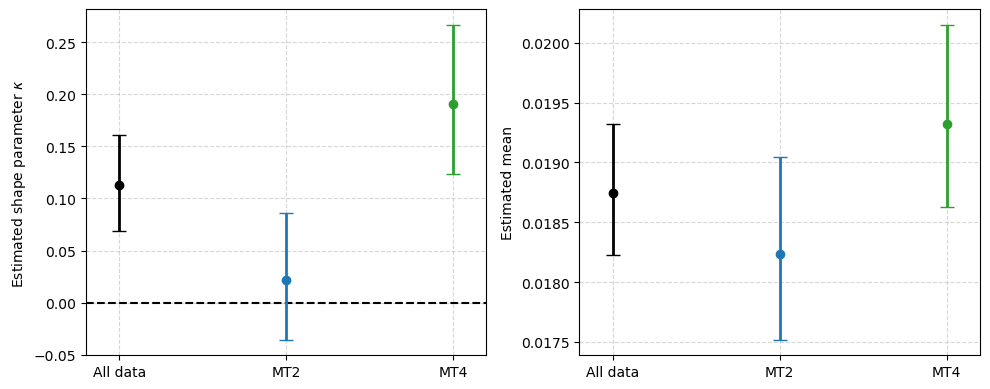

In [6]:
#Different lines
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10, 4))
colours = ['tab:blue','tab:green']
ax1.plot(np.linspace(-0.2,2.2,10),np.zeros(10),'--',color='black')

#All data
k_mle, ci_left, ci_right = mle_ci_k(data_ben['s'],0.1,-0.1,0.4)
ax1.errorbar(x=0, y=k_mle, yerr=[[k_mle-ci_left], [ci_right-k_mle]], fmt='o', elinewidth=2, capsize=5,color='black')
mean_mle, mean_left, mean_right = mle_ci_mean(data_ben['s'],0.015,0.01,0.03)
ax2.errorbar(x=0, y=mean_mle, yerr=[[mean_mle-mean_left], [mean_right-mean_mle]], fmt='o', elinewidth=2, capsize=5,color='black')

for i in range(2):
    k_mle, ci_left, ci_right = mle_ci_k(data_ben.loc[data_ben['cell_type']==i,'s'],0.1,-0.1,0.4)
    ax1.errorbar(x=i+1, y=k_mle, yerr=[[k_mle-ci_left], [ci_right-k_mle]], fmt='o', elinewidth=2, capsize=5,color=colours[i])
    mean_mle, mean_left, mean_right = mle_ci_mean(data_ben.loc[data_ben['cell_type']==i,'s'],0.015,0.01,0.03)
    ax2.errorbar(x=i+1, y=mean_mle, yerr=[[mean_mle-mean_left], [mean_right-mean_mle]], fmt='o', elinewidth=2, capsize=5,color=colours[i])


#Format
for ax in (ax1,ax2):
    ax.set_xlim(-0.2, 2.2)
    ax.set_xticks(ticks=[0,1,2],labels=['All data','MT2','MT4'])
    ax.grid(True, linestyle='--', alpha=0.5)
ax1.set_ylabel("Estimated shape parameter $\kappa$")
ax2.set_ylabel("Estimated mean")
plt.tight_layout()
plt.show()

MT2 has exponential, MT4 has heavy-tailed.   
Significantly higher effect sizes in MT4.

#### Evolutionary lines

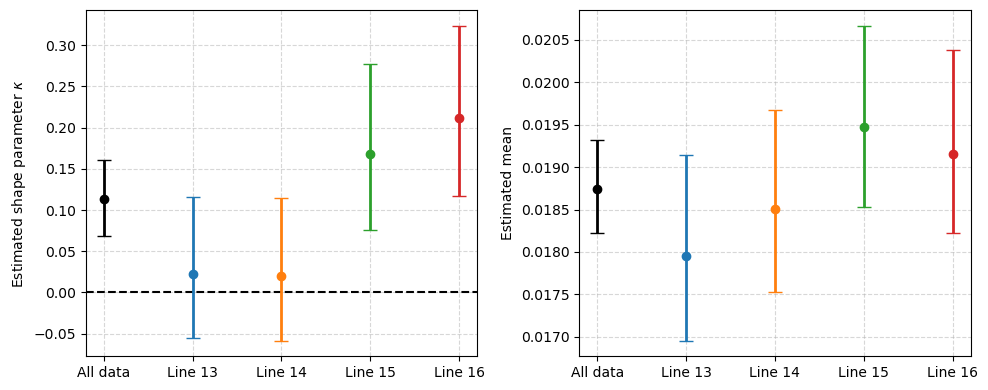

In [7]:
#Different lines
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10, 4))
colours = ['tab:blue','tab:orange','tab:green','tab:red']
ax1.plot(np.linspace(-0.2,4.2,10),np.zeros(10),'--',color='black')

#All data
k_mle, ci_left, ci_right = mle_ci_k(data_ben['s'],0.1,-0.1,0.4)
ax1.errorbar(x=0, y=k_mle, yerr=[[k_mle-ci_left], [ci_right-k_mle]], fmt='o', elinewidth=2, capsize=5,color='black')
mean_mle, mean_left, mean_right = mle_ci_mean(data_ben['s'],0.015,0.01,0.03)
ax2.errorbar(x=0, y=mean_mle, yerr=[[mean_mle-mean_left], [mean_right-mean_mle]], fmt='o', elinewidth=2, capsize=5,color='black')

for i, line in enumerate([13,14,15,16]):
    k_mle, ci_left, ci_right = mle_ci_k(data_ben.loc[data_ben['line']==line,'s'],0.1,-0.1,0.4)
    ax1.errorbar(x=i+1, y=k_mle, yerr=[[k_mle-ci_left], [ci_right-k_mle]], fmt='o', elinewidth=2, capsize=5,color=colours[i])
    mean_mle, mean_left, mean_right = mle_ci_mean(data_ben.loc[data_ben['line']==line,'s'],0.015,0.01,0.03)
    ax2.errorbar(x=i+1, y=mean_mle, yerr=[[mean_mle-mean_left], [mean_right-mean_mle]], fmt='o', elinewidth=2, capsize=5,color=colours[i])


#Format
for ax in (ax1,ax2):
    ax.set_xlim(-0.2, 4.2)
    ax.set_xticks(ticks=[0,1,2,3,4],labels=['All data','Line 13','Line 14','Line 15','Line 16'])
    ax.grid(True, linestyle='--', alpha=0.5)
ax1.set_ylabel("Estimated shape parameter $\kappa$")
ax2.set_ylabel("Estimated mean")
plt.tight_layout()
plt.show()

Those in MT2 lines have exponential shape, those in MT4 have heavy-tails.   
Effect sizes not significantly different (slightly higher in 15 than 13).

#### Mutation types

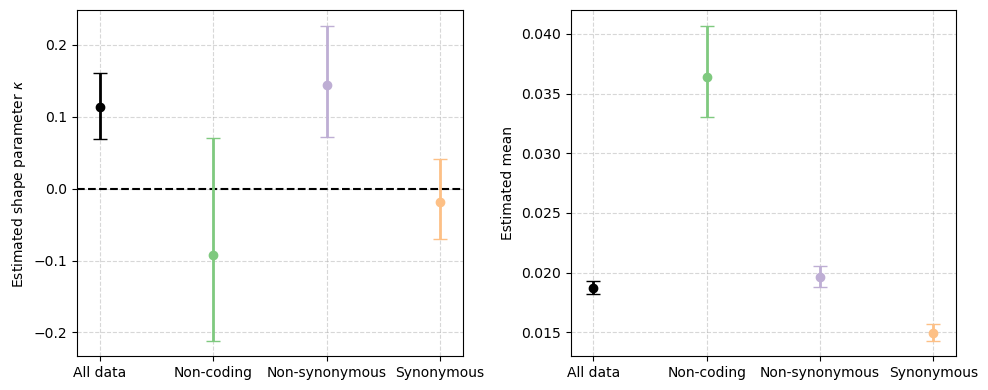

In [8]:
#Different mutation types
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10, 4))
cmap = plt.colormaps['Accent']
colours = list(cmap(np.linspace(0, 0.7, 6)))
mut_types = ['Non-coding','Non-synonymous','Synonymous']
ax1.plot(np.linspace(-0.2,3.2,10),np.zeros(10),'--',color='black')

#All data
k_mle, ci_left, ci_right = mle_ci_k(data_ben['s'],0.1,-0.5,0.4)
ax1.errorbar(x=0, y=k_mle, yerr=[[k_mle-ci_left], [ci_right-k_mle]], fmt='o', elinewidth=2, capsize=5,color='black')
mean_mle, mean_left, mean_right = mle_ci_mean(data_ben['s'],0.015,0.01,0.03)
ax2.errorbar(x=0, y=mean_mle, yerr=[[mean_mle-mean_left], [mean_right-mean_mle]], fmt='o', elinewidth=2, capsize=5,color='black')

for i, type in enumerate(mut_types):
    k_mle, ci_left, ci_right = mle_ci_k(data_ben.loc[data_ben['muttype']==type,'s'],0.1,-0.6,0.4)
    ax1.errorbar(x=i+1, y=k_mle, yerr=[[k_mle-ci_left], [ci_right-k_mle]], fmt='o', elinewidth=2, capsize=5,color=colours[i])
    mean_mle, mean_left, mean_right = mle_ci_mean(data_ben.loc[data_ben['muttype']==type,'s'],0.015,0.01,0.06)
    ax2.errorbar(x=i+1, y=mean_mle, yerr=[[mean_mle-mean_left], [mean_right-mean_mle]], fmt='o', elinewidth=2, capsize=5,color=colours[i])



#Format
for ax in (ax1,ax2):
    ax.set_xlim(-0.2, 3.2)
    ax.set_xticks(ticks=[0,1,2,3],labels=np.concat((['All data'],mut_types)))
    ax.grid(True, linestyle='--', alpha=0.5)
ax1.set_ylabel("Estimated shape parameter $\kappa$")
ax2.set_ylabel("Estimated mean")
plt.tight_layout()
plt.show()

Non-coding have significantly higher effect sizes than other substitutions.  
Non-synonymous have heavy-tails and significantly higher effect sizes than synonymous.   
Not enough data for nonsense, or indels.  

#### Number of parallel lines

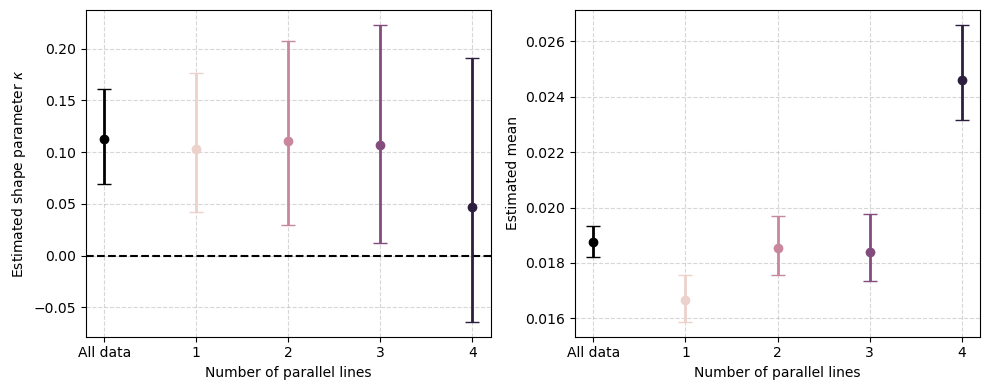

In [9]:
#Different parallelism
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(10, 4))
colours = sns.color_palette("ch:", n_colors=4).as_hex()
ax1.plot(np.linspace(-0.2,4.2,10),np.zeros(10),'--',color='black')

#All data
k_mle, ci_left, ci_right = mle_ci_k(data_ben['s'],0.1,-0.5,0.4)
ax1.errorbar(x=0, y=k_mle, yerr=[[k_mle-ci_left], [ci_right-k_mle]], fmt='o', elinewidth=2, capsize=5,color='black')
mean_mle, mean_left, mean_right = mle_ci_mean(data_ben['s'],0.015,0.01,0.03)
ax2.errorbar(x=0, y=mean_mle, yerr=[[mean_mle-mean_left], [mean_right-mean_mle]], fmt='o', elinewidth=2, capsize=5,color='black')

for i in range(1,5):
    k_mle, ci_left, ci_right = mle_ci_k(data_ben.loc[data_ben['number_of_lines']==i,'s'],0.1,-0.6,0.4)
    ax1.errorbar(x=i, y=k_mle, yerr=[[k_mle-ci_left], [ci_right-k_mle]], fmt='o', elinewidth=2, capsize=5,color=colours[i-1])
    mean_mle, mean_left, mean_right = mle_ci_mean(data_ben.loc[data_ben['number_of_lines']==i,'s'],0.015,0.01,0.06)
    ax2.errorbar(x=i, y=mean_mle, yerr=[[mean_mle-mean_left], [mean_right-mean_mle]], fmt='o', elinewidth=2, capsize=5,color=colours[i-1])


#Format
for ax in (ax1,ax2):
    ax.set_xlim(-0.2, 4.2)
    ax.set_xticks(ticks=[0,1,2,3,4],labels=['All data','1','2','3','4'])
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xlabel('Number of parallel lines')
ax1.set_ylabel("Estimated shape parameter $\kappa$")
ax2.set_ylabel("Estimated mean")
plt.tight_layout()
plt.show()

All have heavy tails except in all 4 lines are exponential.  
Those in 4 lines significantly higher effect sizes.  
Those in only 1 line significantly lower.  

### Combined likelihood

In [10]:
#Define custom likelihood function with scale parameters for each line, and delta parameters for mutation types and parallelism
def neg_ll_customised(params):
    k_mt2,k_mt4,t,dt_14,dt_15,dt_16,dt_nc,dt_s,dt_n,dt_i,dt_d,dt_p2,dt_p3,dt_p4 = params
    dt_line = [0,dt_14,dt_15,dt_16]
    dt_type = [dt_nc,0,dt_s,dt_n,dt_i,dt_d]
    dt_parallel = [0,dt_p2,dt_p3,dt_p4]

    log_likelihood = 0
    for i,line in enumerate([13,14,15,16]):
        data_line = data_ben[data_ben['line']==line]
        for j,mut_type in enumerate(['Non-coding','Non-synonymous','Synonymous','Nonsense','Insertion','Deletion']):
            data_type = data_line[data_line['muttype']==mut_type]
            for l,num_lines in enumerate([1,2,3,4]):
                data_parallel = data_type[data_type['number_of_lines']==num_lines]
                if line == 13 or line == 14:
                    log_likelihood += np.sum(genpareto.logpdf(data_parallel['s'], k_mt2, 0, t+dt_line[i]+dt_type[j]+dt_parallel[l]))
                else:
                    log_likelihood += np.sum(genpareto.logpdf(data_parallel['s'], k_mt4, 0, t+dt_line[i]+dt_type[j]+dt_parallel[l]))
    return -log_likelihood

#Maximise over all parameters
initial = [0.1,0.1,0.02,0,0,0,0,0,0,0,0,0,0,0]
bounds = [(-0.04,0.4),(-0.04,0.4),(0.01,0.05),(-0.0001,0.002),(-0.0001480,0.002),(-0.00110,0.0001),(-0.001,0.03),(-0.005,0.001),(-0.0063891,0.001),(-0.0079340,0.0001),(-0.0001,0.01),(-0.001,0.002),(-0.002,0.001),(-0.001,0.01)]
result = minimize(fun=neg_ll_customised, x0=initial, method='L-BFGS-B', bounds=bounds)

KeyboardInterrupt: 

In [ ]:
#Results and likelihood ratio tests
print(f'\nEstimated shape parameter for MT2, k = {result.x[0]} (exponential above, k~0)')
print(f'\nEstimated shape parameter for MT4, k = {result.x[1]} (heavy-tailed above, k=0)')
print(f'\nEstimated scale parameter for non-syn, line 13, t = {result.x[2]}')
print(f'Therefore estimated mean = {result.x[2]/(1-result.x[0])}')
print(f'Therefore mean (MT2) = {result.x[2]/(1-result.x[0])}, mean (MT4) = {result.x[2]/(1-result.x[1])}')
    
for i, line in enumerate([14,15,16]):
    print(f'\nEstimated dt for line {line} = {result.x[3+i]}')
    if line == 14:
        print(f'Therefore d(mean) = {result.x[3+i]/(1-result.x[0])}')
    else:
        print(f'Therefore d(mean) = {result.x[3+i]/(1-result.x[1])}')
    result_simple = result.x.copy()
    result_simple[3+i] = 0
    lr_stat = 2 * (neg_ll_customised(result_simple) - neg_ll_customised(result.x))
    p_value = stats.chi2.sf(lr_stat, 1)
    print(f'p-value = {p_value:.3f} (ns)')

for i, type in enumerate(['Non-coding','Synonymous','Nonsense','Insertion','Deletion']):
    print(f'\nEstimated dt for {type} mutations = {result.x[6+i]}')
    print(f'Therefore d(mean, MT2) = {result.x[6+i]/(1-result.x[0])}, d(mean, MT4) = {result.x[6+i]/(1-result.x[1])}')
    result_simple = result.x.copy()
    result_simple[6+i] = 0
    lr_stat = 2 * (neg_ll_customised(result_simple) - neg_ll_customised(result.x))
    p_value = stats.chi2.sf(lr_stat, 1)
    if i>1:
        print(f'p-value = {p_value} (ns)')
    else:
        print(f'p-value = {p_value} (****)')

for l,num_lines in enumerate([2,3,4]):
    print(f'\nEstimated dt for {num_lines} parallel lines = {result.x[11+l]}')
    print(f'Therefore d(mean, MT2) = {result.x[11+l]/(1-result.x[0])}, d(mean, MT4) = {result.x[11+l]/(1-result.x[1])}')
    result_simple = result.x.copy()
    result_simple[11+l] = 0
    lr_stat = 2 * (neg_ll_customised(result_simple) - neg_ll_customised(result.x))
    p_value = stats.chi2.sf(lr_stat, 1)
    if l==0:
        print(f'p-value = {p_value} (*)')
    elif l==1:
        print(f'p-value = {p_value} (ns)')
    else:
        print(f'p-value = {p_value} (****)')


Estimated shape parameter for MT2, k = -0.02821079512169454 (exponential above, k~0)

Estimated shape parameter for MT4, k = 0.07713944871051341 (heavy-tailed above, k=0)

Estimated scale parameter for non-syn, line 13, t = 0.017277942616332843
Therefore estimated mean = 0.016803891476638213
Therefore mean (MT2) = 0.016803891476638213, mean (MT4) = 0.01872215969378133

Estimated dt for line 14 = 0.0013343121903043966
Therefore d(mean) = 0.0012977029580266888
p-value = 0.052 (ns)

Estimated dt for line 15 = -0.000148
Therefore d(mean) = -0.00016037092472227123
p-value = 0.727 (ns)

Estimated dt for line 16 = -0.0011
Therefore d(mean) = -0.0011919460621249891
p-value = 0.046 (ns)

Estimated dt for Non-coding mutations = 0.016169980368588736
Therefore d(mean, MT2) = 0.015726328147211224, d(mean, MT4) = 0.017521585840888837
p-value = 2.5211308384923394e-19 (****)

Estimated dt for Synonymous mutations = -0.0037821686862687083
Therefore d(mean, MT2) = -0.0036783981496917345, d(mean, MT4) =

Standard significance levels are:

      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Note that the Bonferroni correction has been applied to each analysis. Hence, we multiplied the significance limits by 3 for lines, and parallelism, and by 5 for mutation types.

## General Linear Model with gamma distribution for beneficial tail

In [19]:
#GLM
formula = "s ~ C(cell_type) + C(line) + C(muttype) + C(number_of_lines)"
model = smf.glm(formula, data=data_ben, family=sm.families.Gamma(link=sm.families.links.Log())).fit()

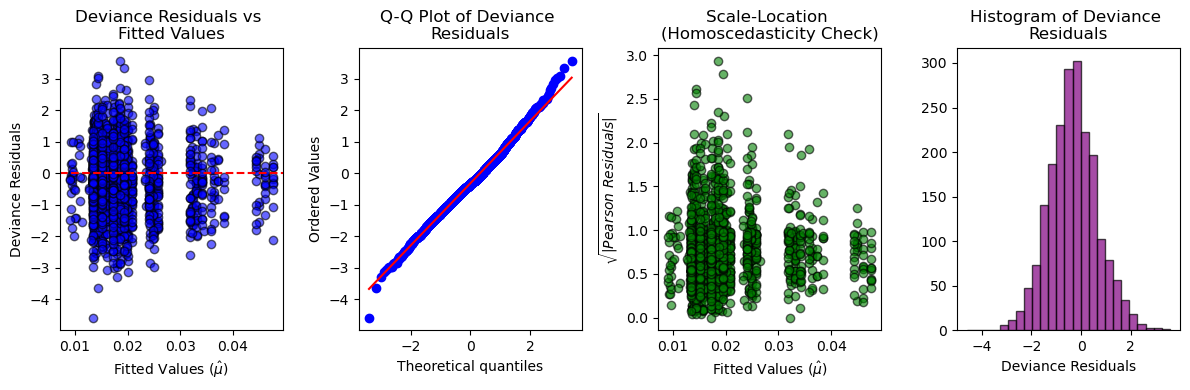

In [20]:
#Residuals plots to check fit
res_deviance = model.resid_deviance
res_pearson = model.resid_pearson

fig, axes = plt.subplots(1,4,figsize=(12, 4))

#Deviance Residuals vs Fitted Values
axes[0].scatter(model.fittedvalues, res_deviance, alpha=0.6, color='blue', edgecolors='k')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Deviance Residuals vs \nFitted Values')
axes[0].set_xlabel('Fitted Values ($\hat{\mu}$)')
axes[0].set_ylabel('Deviance Residuals')

#Q-Q Plot of Deviance Residuals
stats.probplot(res_deviance, dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot of Deviance \nResiduals')

#cale-Location Plot
axes[2].scatter(model.fittedvalues, np.sqrt(np.abs(res_pearson)), alpha=0.6, color='green', edgecolors='k')
axes[2].set_title('Scale-Location \n(Homoscedasticity Check)')
axes[2].set_xlabel('Fitted Values ($\hat{\mu}$)')
axes[2].set_ylabel('$\sqrt{|Pearson\ Residuals|}$')

#Histogram of Deviance Residuals
axes[3].hist(res_deviance, bins=25, edgecolor='black', color='purple', alpha=0.7)
axes[3].set_title('Histogram of Deviance \nResiduals')
axes[3].set_xlabel('Deviance Residuals')

plt.tight_layout()
plt.show()

In [21]:
#Joint Wald test for effect of each predictor
overall_tests = model.wald_test_terms(scalar=True)
print(overall_tests.summary_frame())

                          chi2        P>chi2  df constraint
Intercept           325.722806  8.210773e-73              1
C(cell_type)          0.142333  7.059728e-01              1
C(line)               1.265991  7.372243e-01              3
C(muttype)          126.749340  1.164678e-25              5
C(number_of_lines)   26.229591  8.537931e-06              3


Significant (p<0.05) categories are the mutation type and the number of lines or parallelism.

In [22]:
#Mutation type pairwise t-test p-values
pairwise_results_muttype = model.t_test_pairwise('C(muttype)', method='bonferroni').result_frame
pairwise_results_muttype[pairwise_results_muttype['reject-bonferroni']==True]

,coef,std err,z,P>|z|,Conf. Int. Low,Conf. Int. Upp.,pvalue-bonferroni,reject-bonferroni
Insertion-Deletion,-0.941699,0.307692,-3.060520,2.209528e-03,-1.544764,-0.338633,3.314292e-02,True
Non-coding-Insertion,1.259335,0.244831,5.143699,2.693809e-07,0.779476,1.739194,4.040714e-06,True
Non-synonymous-Non-coding,-0.613329,0.085672,-7.159066,8.122841e-13,-0.781242,-0.445415,1.218426e-11,True
Nonsense-Non-coding,-1.220220,0.243930,-5.002333,5.664066e-07,-1.698314,-0.742125,8.496099e-06,True
Synonymous-Non-coding,-0.867222,0.084499,-10.263079,1.033581e-24,-1.032837,-0.701606,1.550371e-23,True
Synonymous-Non-synonymous,-0.253893,0.048977,-5.183931,2.172577e-07,-0.349886,-0.157900,3.258865e-06,True


Significant pairwise differences are the same as with all non-coding pairs except noncoding-deletion, and also nonsynonymous-synonymous, and weak insertion-deletion.

In [23]:
#Number of lines pairwise t-test p-values
pairwise_results_lines = model.t_test_pairwise('C(number_of_lines)', method='bonferroni').result_frame
pairwise_results_lines[pairwise_results_lines['reject-bonferroni']==True]

,coef,std err,z,P>|z|,Conf. Int. Low,Conf. Int. Upp.,pvalue-bonferroni,reject-bonferroni
4-1,0.329135,0.069231,4.754127,0.000002,0.193444,0.464826,0.000012,True
4-2,0.213365,0.073387,2.907381,0.003645,0.069528,0.357202,0.021868,True
4-3,0.331985,0.077641,4.275913,0.000019,0.179812,0.484158,0.000114,True


Significant pairwise differences are all those involving mutations in all 4 lines.

## Non-parametric rank test for beneficial tail

In [24]:
#Kruskal-Wallis non-parametric test for each characteristic individually
kw_results = []
characteristics = ['cell_type', 'line', 'muttype', 'number_of_lines']

for char in characteristics:
    groups = [group['s'].values for name, group in data_ben.groupby(char)]
    stat, p_val = stats.kruskal(*groups)
    kw_results.append({'characteristic': char,'statistic': stat,'p_value': p_val,'significant': p_val < 0.05})

results_df = pd.DataFrame(kw_results)
print(results_df)

#Post-hoc pairwise comparisons using Dunn's test 
significant_chars = results_df[results_df['significant']]['characteristic'].tolist()
for char in significant_chars:
    print(f"\nPost-hoc test for {char}:")
    dunn_results = sp.posthoc_dunn(data_ben, val_col='s', group_col=char, p_adjust='bonferroni')
    print(dunn_results)

    characteristic  statistic       p_value  significant
0        cell_type   0.926818  3.356912e-01        False
1             line   1.230484  7.457027e-01        False
2          muttype  92.756386  1.770151e-18         True
3  number_of_lines  20.708060  1.210433e-04         True

Post-hoc test for muttype:
                Deletion  Insertion    Non-coding  Non-synonymous  Nonsense  \
Deletion        1.000000   0.665554  5.341564e-01    1.000000e+00  1.000000   
Insertion       0.665554   1.000000  1.568384e-04    9.555764e-01  1.000000   
Non-coding      0.534156   0.000157  1.000000e+00    8.146772e-13  0.000617   
Non-synonymous  1.000000   0.955576  8.146772e-13    1.000000e+00  1.000000   
Nonsense        1.000000   1.000000  6.172300e-04    1.000000e+00  1.000000   
Synonymous      1.000000   1.000000  2.548705e-19    7.319905e-02  1.000000   

                  Synonymous  
Deletion        1.000000e+00  
Insertion       1.000000e+00  
Non-coding      2.548705e-19  
Non-synon

Similar results as with the GLM.   
For mutation types, insertion-deletion is no longer significant, non-coding-nonsense is a bit less, and synonymous-non-synonymous is now weak (p=0.073).  
For number of lines, 4-2 is a bit more significant, and 4-3 a bit less.   

## ANOVA test for all mutations

In [25]:
#ANOVA linear model: cell type, line number, mutation type, parallelism
formula = "s ~ C(cell_type) + C(line) + C(muttype) + C(number_of_lines)"
model = ols(formula, data=data_indexed).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

print(anova_table)

                      sum_sq      df          F        PR(>F)
C(cell_type)        0.000449     1.0   0.791875  3.735863e-01
C(line)             0.000652     3.0   0.383662  7.647872e-01
C(muttype)          0.111102     5.0  39.225702  1.750942e-39
C(number_of_lines)  0.004221     3.0   2.483643  5.898741e-02
Residual            2.311210  4080.0        NaN           NaN


Only significant category is the mutation type (p<0.05).

In [26]:
#Post-hoc test: Tukey's Honestly Significant Difference
tukey_test = pairwise_tukeyhsd(endog=data_indexed["s"], groups=data_indexed["muttype"], alpha=0.05)
tukey_df = pd.DataFrame(data=tukey_test.summary().data[1:],columns=tukey_test.summary().data[0]) #convert summary to df
tukey_df = tukey_df.rename(columns={'group1':'type 1','group2':'type 2'})
tukey_df[tukey_df["reject"] == True]

,type 1,type 2,meandiff,p-adj,lower,upper,reject
1,Deletion,Non-coding,0.0166,0.0001,0.0063,0.0269,True
5,Insertion,Non-coding,0.0190,0.0001,0.0072,0.0308,True
9,Non-coding,Non-synonymous,-0.0193,0.0000,-0.0238,-0.0148,True
10,Non-coding,Nonsense,-0.0274,0.0000,-0.0377,-0.0171,True
11,Non-coding,Synonymous,-0.0213,0.0000,-0.0258,-0.0169,True


Significant pairwise differences are all those involving non-coding mutations.

## Non-parametric rank test for all mutations

In [27]:
#Kruskal-Wallis non-parametric test for each characteristic individually
kw_results = []
characteristics = ['cell_type', 'line', 'muttype', 'number_of_lines']

for char in characteristics:
    groups = [group['s'].values for name, group in data_indexed.groupby(char)]
    stat, p_val = stats.kruskal(*groups)
    kw_results.append({'characteristic': char,'statistic': stat,'p_value': p_val,'significant': p_val < 0.05})

results_df = pd.DataFrame(kw_results)
print(results_df)

#Post-hoc pairwise comparisons using Dunn's test 
significant_chars = results_df[results_df['significant']]['characteristic'].tolist()
for char in significant_chars:
    print(f"\nPost-hoc test for {char}:")
    dunn_results = sp.posthoc_dunn(data_indexed, val_col='s', group_col=char, p_adjust='bonferroni')
    print(dunn_results)

    characteristic  statistic       p_value  significant
0        cell_type   0.000946  9.754683e-01        False
1             line   0.085781  9.934873e-01        False
2          muttype  99.938177  5.446118e-20         True
3  number_of_lines   7.306116  6.275512e-02        False

Post-hoc test for muttype:
                Deletion  Insertion    Non-coding  Non-synonymous  \
Deletion        1.000000   1.000000  4.583349e-03    1.000000e+00   
Insertion       1.000000   1.000000  1.268850e-01    1.000000e+00   
Non-coding      0.004583   0.126885  1.000000e+00    2.835210e-18   
Non-synonymous  1.000000   1.000000  2.835210e-18    1.000000e+00   
Nonsense        0.835553   0.432842  1.795286e-08    3.272126e-01   
Synonymous      1.000000   1.000000  1.862601e-20    1.000000e+00   

                    Nonsense    Synonymous  
Deletion        8.355535e-01  1.000000e+00  
Insertion       4.328422e-01  1.000000e+00  
Non-coding      1.795286e-08  1.862601e-20  
Non-synonymous  3.27212

Mostly same patterns with non-coding mutations being significantly higher.     
Non-coding - deletion is now *** instead of ****  
Non-coding - insertion is no longer significant

## Variance test for all mutations

In [28]:
#Levene's test for homogeneity of variance
kw_results = []
characteristics = ['cell_type', 'line', 'muttype', 'number_of_lines']

for char in characteristics:
    groups = [group['s'].values for name, group in data_indexed.groupby(char)]
    stat, p_value = stats.levene(*groups)
    kw_results.append({'characteristic': char,'statistic': stat,'p_value': p_value,'significant': p_value<0.05})

results_df = pd.DataFrame(kw_results)
print(results_df)

    characteristic  statistic       p_value  significant
0        cell_type   3.099049  7.841277e-02        False
1             line   1.101151  3.472918e-01        False
2          muttype  25.252507  3.673697e-25         True
3  number_of_lines  18.581175  5.714739e-12         True


Significant difference in the variance of mutation types, and parallelism.   
Agree with Bartlett's and Fligner-Killeen tests.  

In [29]:
#Pairwise Levene's tests for mutation types with Bonferroni correction
pairs = list(itertools.combinations(['Non-coding','Non-synonymous','Synonymous','Nonsense','Insertion','Deletion'], 2))
num_comparisons = len(pairs)

print(f"{'Pair':<15} | {'Levene Stat':<12} | {'Raw p-value':<12} | {'Adjusted p-value':<15} | Significant")
print("-" * 80)

for g1, g2 in pairs:
    stat, p_val = stats.levene(data_indexed.loc[data_indexed['muttype']==g1,'s'].values, data_indexed.loc[data_indexed['muttype']==g2,'s'].values)
    p_adjusted = min(p_val * num_comparisons, 1.0) #Bonferroni correction
    significant = p_adjusted<0.05
    if significant:
        print(f"{g1} vs {g2:<5} | {stat:<12.4f} | {p_val:<12.4e} | {p_adjusted:<15.4e} | {significant}")

Pair            | Levene Stat  | Raw p-value  | Adjusted p-value | Significant
--------------------------------------------------------------------------------
Non-coding vs Non-synonymous | 53.4356      | 3.8799e-13   | 5.8198e-12      | True
Non-coding vs Synonymous | 133.4745     | 4.8965e-30   | 7.3447e-29      | True
Non-coding vs Nonsense | 10.9044      | 1.0715e-03   | 1.6072e-02      | True
Non-coding vs Insertion | 18.6934      | 2.0999e-05   | 3.1499e-04      | True
Non-synonymous vs Synonymous | 16.1310      | 6.0287e-05   | 9.0431e-04      | True
Synonymous vs Insertion | 8.6921       | 3.2324e-03   | 4.8486e-02      | True
Insertion vs Deletion | 11.7674      | 9.1975e-04   | 1.3796e-02      | True


In [30]:
#Pairwise Levene's tests for parallelism with Bonferroni correction
pairs = list(itertools.combinations([1,2,3,4], 2))
num_comparisons = len(pairs)

print(f"{'Pair':<15} | {'Levene Stat':<12} | {'Raw p-value':<12} | {'Adjusted p-value':<15} | Significant")
print("-" * 80)

for g1, g2 in pairs:
    stat, p_val = stats.levene(data_indexed.loc[data_indexed['number_of_lines']==g1,'s'].values, data_indexed.loc[data_indexed['number_of_lines']==g2,'s'].values)
    p_adjusted = min(p_val * num_comparisons, 1.0) #Bonferroni correction
    significant = p_adjusted<0.05
    if significant:
        print(f"{g1} vs {g2:<5} | {stat:<12.4f} | {p_val:<12.4e} | {p_adjusted:<15.4e} | {significant}")

Pair            | Levene Stat  | Raw p-value  | Adjusted p-value | Significant
--------------------------------------------------------------------------------
1 vs 4     | 53.1009      | 4.4072e-13   | 2.6443e-12      | True
2 vs 4     | 28.0336      | 1.3428e-07   | 8.0568e-07      | True
3 vs 4     | 16.7565      | 4.4737e-05   | 2.6842e-04      | True


## Plots

In [31]:
def plot_box_plot(ax, data, x):
    ax.plot(x+np.linspace(-0.3,0.3,5),np.median(data)+np.zeros(5),'--',color='black',linewidth=1)
    q1 = np.percentile(data,25)
    q2 = np.percentile(data,75)
    ax.plot(x+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=1)
    ax.plot(x+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=1)
    ax.plot(x+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=1)
    ax.plot(x+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=1)
    ax.plot(x+np.zeros(5),np.linspace(q2,data.max(),5),'--',color='black',linewidth=1)
    ax.plot(x+np.zeros(5),np.linspace(data.min(),q1,5),'--',color='black',linewidth=1)
    ax.plot(x+np.linspace(-0.1,0.1,5),data.max()+np.zeros(5),'--',color='black',linewidth=1)
    ax.plot(x+np.linspace(-0.1,0.1,5),data.min()+np.zeros(5),'--',color='black',linewidth=1)

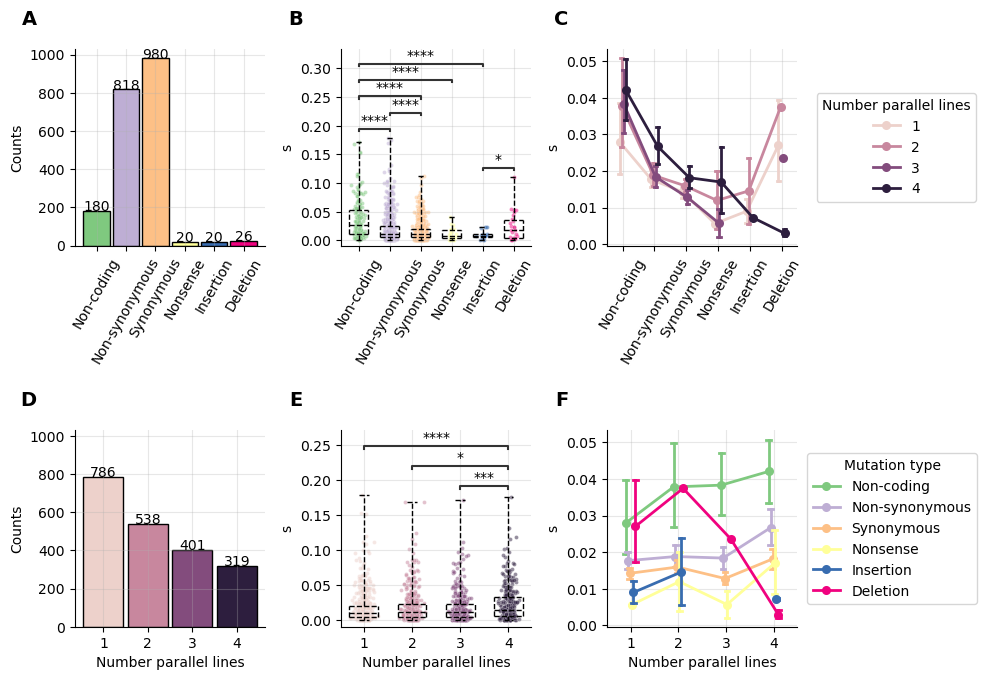

In [38]:
#Beneficial tail
fig, axes = plt.subplots(2,3,figsize=(10,7))
axes = axes.flatten()
axes[3].sharey(axes[0])
axes[5].sharey(axes[2])

mutation_types = ['Non-coding','Non-synonymous','Synonymous','Nonsense','Insertion','Deletion']

#Histogram of mutation types
counts, bins, patches = axes[0].hist(data_ben['muttype'],bins=np.arange(-0.5,6.5,1),rwidth=0.9,edgecolor='black')
axes[0].set_ylabel('Counts')
cmap = plt.colormaps['Accent']
colours = list(cmap(np.linspace(0, 0.7, 6)))
for patch, colour in zip(patches, colours):
    patch.set_facecolor(colour)
for i in range(6):
    axes[0].text(x=i,y=counts[i],s=counts[i].astype(int),ha='center')

#Box plots for mutation types
for i,type in enumerate(data_ben['muttype'].unique()):
    data_indexed_ben_type = data_ben[data_ben['muttype']==type]
    sns.scatterplot(x=np.random.normal(i, 0.08, size=len(data_indexed_ben_type)), y=data_indexed_ben_type['s'],ax=axes[1],alpha=0.5,s=8,color=colours[i],edgecolors='white',legend=False)
    plot_box_plot(axes[1], data_indexed_ben_type['s'], i)
axes[1].set_xticks(ticks=np.arange(6),labels=data_ben['muttype'].unique())

#Significance annotations for mutation types
pairs = []
pvalues = []

for i,row in (pairwise_results_muttype[pairwise_results_muttype['reject-bonferroni']]).iterrows():
    types = [char for char in mutation_types if char in str(row.name)]
    pairs.append((types[0],types[1]))
    pvalues.append(row['pvalue-bonferroni'])

annotator = Annotator(axes[1], pairs, data=data_ben, x='muttype', y='s')
annotator.configure(test=None, text_format="star", loc="inside", verbose=False)
annotator.set_pvalues(pvalues)
annotator.annotate()

#Two dimensional pointplot for mutation types (Means ± 95% CI)
sns.pointplot(data=data_ben, x="muttype", y="s", hue="number_of_lines", palette='ch:', ax=axes[2], dodge=0.2, markersize=5, linewidth=2, capsize=0.1)
axes[2].set_xlabel('')
axes[2].legend(loc='center left', bbox_to_anchor=(1.1, 0.5), borderaxespad=0, title='Number parallel lines')

#Histogram of parallelism
counts, bins, patches = axes[3].hist(data_ben['number_of_lines'],bins=np.arange(0.5,5.5,1),rwidth=0.9,edgecolor='black')
axes[3].set_ylabel('Counts')
colours = sns.color_palette("ch:", n_colors=4).as_hex()
for patch, colour in zip(patches, colours):
    patch.set_facecolor(colour)
for i in range(4):
    axes[3].text(x=i+1,y=counts[i],s=counts[i].astype(int),ha='center')
axes[3].set_xticks(ticks=np.arange(1,5),labels=np.arange(1,5))

#Box plots of parallelism
for i in range(4):
    data_indexed_ben_num = data_ben[data_ben['number_of_lines']==i+1]
    sns.scatterplot(x=np.random.normal(i, 0.08, size=len(data_indexed_ben_num)), y=data_indexed_ben_num['s'],ax=axes[4],alpha=0.5,s=8,color=colours[i],edgecolors='white',legend=False)
    plot_box_plot(axes[4], data_indexed_ben_num['s'], i)
axes[4].set_xticks(ticks=np.arange(4),labels=np.arange(1,5))

#Significance annotations for parallelism
pairs = []
pvalues = []
for i,row in (pairwise_results_lines[pairwise_results_lines['reject-bonferroni']==True]).iterrows():
    pairs.append((int(row.name.split('-')[0]),int(row.name.split('-')[1])))
    pvalues.append(row['pvalue-bonferroni'])

annotator = Annotator(axes[4], pairs, data=data_ben, x='number_of_lines', y='s')
annotator.configure(test=None, text_format="star", loc="inside", verbose=False)
annotator.set_pvalues(pvalues)
annotator.annotate()

#Two dimensional pointplot for parallelism (Means ± 95% CI)
cmap = plt.colormaps['Accent']
colours = list(cmap(np.linspace(0, 0.7, 6)))
sns.pointplot(data=data_ben, x="number_of_lines", y="s", hue="muttype", hue_order=mutation_types, palette=colours, ax=axes[5], dodge=0.2, markersize=5, linewidth=2, capsize=0.1)
axes[5].set_xlabel('')
axes[5].legend(loc='center left', bbox_to_anchor=(1.05, 0.5), borderaxespad=0, title='Mutation type')

#Format
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(alpha=0.3)
for ax in axes[:3]:
    ax.tick_params(axis='x',rotation=60)
for ax in axes[3:]:
    ax.set_xlabel('Number parallel lines')

labels = ['A','B','C','D','E','F']
for ax, label in zip(axes, labels):
    ax.text(-0.2, 1.2, label, transform=ax.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

plt.tight_layout()
plt.savefig(fig_path + f"/statistics_beneficial.pdf")
plt.show()

Significance annotations from the GLM (though non-synonymous comparisons agree with GPD likelihood, as do non-parallel comparisons except for no * to muts in 2 lines).

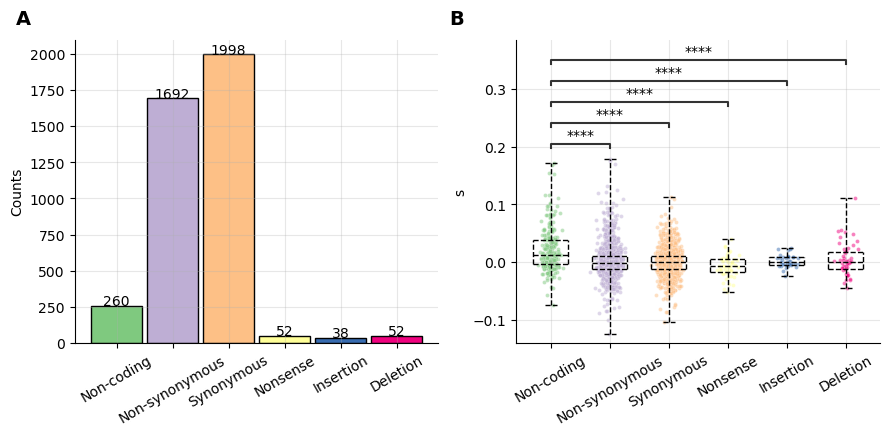

In [ ]:
#All mutations
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(9,4.5))

#Histogram
counts, bins, patches = ax1.hist(data_indexed['muttype'],bins=np.arange(-0.5,6.5,1),rwidth=0.9,edgecolor='black')
ax1.set_ylabel('Counts')
cmap = plt.colormaps['Accent']
colours = list(cmap(np.linspace(0, 0.7, 6)))
for patch, colour in zip(patches, colours):
    patch.set_facecolor(colour)
for i in range(6):
    ax1.text(x=i,y=counts[i],s=counts[i].astype(int),ha='center')
ax1.text(-0.12, 1.1, 'A', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


#Box plots for mutation types
for i,type in enumerate(data_indexed['muttype'].unique()):
    data_indexed_type = data_indexed[data_indexed['muttype']==type]
    sns.scatterplot(x=np.random.normal(i, 0.08, size=len(data_indexed_type)), y=data_indexed_type['s'],ax=ax2,alpha=0.5,s=8,color=colours[i],edgecolors='white',legend=False)
    plot_box_plot(ax2, data_indexed_type['s'], i)
ax2.set_xticks(ticks=np.arange(6),labels=data_indexed['muttype'].unique())
ax2.text(1.07, 1.1, 'B', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#Significance annotations
pairs = []
pvalues = []
for i,row in (tukey_df[tukey_df["reject"] == True]).iterrows():
    pairs.append((row['type 1'],row['type 2']))
    pvalues.append(row['p-adj'])

annotator = Annotator(ax2, pairs, data=data_indexed, x='muttype', y='s')
annotator.configure(test=None, text_format="star", loc="inside", verbose=False)
annotator.set_pvalues(pvalues)
annotator.annotate()

#Format
for ax in (ax1,ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(alpha=0.3)
    ax.tick_params(axis='x',rotation=30)

plt.tight_layout()
plt.savefig(fig_path + f"/statistics_all.pdf")
plt.show()

Significance annotations from ANOVA. Agrees with non-parametric test except non-coding deletion would be ** and non-coding insertion would be not significant.

## Fraction of beneficial vs. deleterious mutations

In [ ]:
#Lines
observed_counts = np.zeros((2,4))
for i,line in enumerate([13,14,15,16]):
    data_line = data_indexed[data_indexed['line']==line]
    observed_counts[0,i] = len(data_line[data_line['s']>0])
    observed_counts[1,i] = len(data_line[data_line['s']<0])
chi2_stat, p_value, dof, expected = chi2_contingency(observed_counts)
if p_value<0.05:
    print(f'Significant correlation: p-value = {p_value}')
else:
    print(f'No significant correlation: p-value = {p_value}')

No significant correlation: p-value = 0.6342785099201869


In [ ]:
#Mutation types
observed_counts = np.zeros((2,6))
for i,type in enumerate(['Non-coding','Non-synonymous','Synonymous','Nonsense','Insertion','Deletion']):
    data_type = data_indexed[data_indexed['muttype']==type]
    observed_counts[0,i] = len(data_type[data_type['s']>0])
    observed_counts[1,i] = len(data_type[data_type['s']<0])
chi2_stat, p_value, dof, expected = chi2_contingency(observed_counts)
if p_value<0.05:
    print(f'Significant correlation: p-value = {p_value}')
else:
    print(f'No significant correlation: p-value = {p_value}')

#Look at standardised residuals
table = sm.stats.Table(observed_counts)
adj_residuals = table.standardized_resids
print('Residuals:')
print(np.round(adj_residuals, 2))

Significant correlation: p-value = 2.417637590958654e-08
Residuals:
[[ 6.42 -1.73 -1.13 -1.67  0.33  0.01]
 [-6.42  1.73  1.13  1.67 -0.33 -0.01]]


Significantly more non-coding mutations are beneficial than deleterious. Other types not significant.

In [ ]:
#Parallelism
observed_counts = np.zeros((2,4))
for i,num in enumerate([1,2,3,4]):
    data_num = data_indexed[data_indexed['number_of_lines']==num]
    observed_counts[0,i] = len(data_num[data_num['s']>0])
    observed_counts[1,i] = len(data_num[data_num['s']<0])
chi2_stat, p_value, dof, expected = chi2_contingency(observed_counts)
if p_value<0.05:
    print(f'Significant correlation: p-value = {p_value}')
else:
    print(f'No significant correlation: p-value = {p_value}')

No significant correlation: p-value = 0.06473368969342387
